# Spotify 歌曲热度：清洗、数据划分与第一版模型

目标：仅用 13 个音频与音乐结构字段识别数据记录时 `popularity >= 60` 的歌曲。
原始数据来自用户提供的 archive.zip / tracks.csv。此分析不预测未来热度，也不说明因果。

运行：需要 Python 3、numpy、pandas、scikit-learn、matplotlib、joblib。
将 archive.zip 放在工作目录，或修改 DATA_PATH。结果写到当前目录下 model_results。
保留原数据；本实验对特定音频零值的处理是显式建模假设。

实验方案在查看模型测试结果之前确定：
- 固定随机种子 20261123，目标阈值 60。
- 同名（去首尾空格、合并空白、casefold）且艺人 ID 集合相同的歌曲，或全部 13 个原始特征相同的歌曲，以连通分组方式放在同一集合。缺失歌名不参加同名规则。
- 主实验：版本组按确定性哈希约 60/20/20 划分训练/验证/测试。艺人可以重叠。
- 泛化检查：先把每位艺人按另一确定性哈希约 60/20/20 分配。合作歌曲仅在所有艺人分到同一集合时保留；再排除横跨多个集合的版本组。该实验改变了样本组成，不能把两组分数之差完全归因于艺人泄漏。
- 分类器：固定的逻辑回归、两种事先指定容量的随机森林，以及常数基准。只在验证集选择森林配置与分类阈值。
- 以 Average Precision (AP) 作为主要 PR 汇总指标。它与梯形积分 PR-AUC 不完全相同；报告明确使用 AP。
- 只在验证集上选择最大 F1 的分类阈值，测试集只用于最后评估，不据此返工。

参考：[scikit-learn AP 定义](https://scikit-learn.org/1.7/modules/generated/sklearn.metrics.average_precision_score.html)。

## 本次已执行结果摘要

本节记录随文件交付的这次运行结果。重跑时请查看下方实际输出；更改数据或配置后不要沿用本节静态数字。

| 实验 | 模型 | 测试 AP | Precision | Recall | F1 |
|---|---|---:|---:|---:|---:|
| 版本分组，艺人可重叠 | 常数基准 | 0.0476 | 0.00% | 0.00% | 0.0000 |
| 版本分组，艺人可重叠 | 逻辑回归 | 0.1515 | 16.52% | 37.98% | 0.2303 |
| 版本分组，艺人可重叠 | 随机森林 depth12 | 0.1752 | 20.26% | 39.47% | 0.2677 |
| 艺人完全独立 | 常数基准 | 0.0446 | 0.00% | 0.00% | 0.0000 |
| 艺人完全独立 | 逻辑回归 | 0.1344 | 14.83% | 35.41% | 0.2090 |
| 艺人完全独立 | 随机森林 depth20 | 0.1601 | 19.53% | 30.14% | 0.2370 |

Precision、Recall、F1 使用验证集选择的阈值，常数基准采用 0.5。AP 与此阈值无关。
严格实验排除跨集合合作歌曲及跨集合版本组，样本组成与主实验不同；不是配对比较。
所有模型均只在各自训练集拟合。测试分数没有用于选模型、调阈值或修改特征。
交付前重新加载模型并核对了 1,000 条测试预测、测试标签、评价指标及训练集填补统计。
当前仅完成一次固定划分，尚未进行重复划分、置信区间评估、概率校准或外部数据验证。

In [1]:
from pathlib import Path
from zipfile import ZipFile
from functools import lru_cache
from itertools import combinations
import ast
import hashlib
import json
import platform
import time
import warnings
import numpy as np
import pandas as pd
import sklearn
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, precision_recall_curve,
    precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.exceptions import ConvergenceWarning

SEED = 20261123
THRESHOLD = 60
N_JOBS = 4
DATA_PATH = next((p for p in [Path('archive.zip'), Path.home()/'Downloads'/'archive.zip'] if p.exists()), Path('archive.zip'))
OUT = Path('model_results')
OUT.mkdir(parents=True, exist_ok=True)
AUDIO = ['danceability','energy','tempo','loudness','valence','acousticness','instrumentalness','speechiness','liveness']
FEATURES = AUDIO + ['duration_ms','key','mode','time_signature']
CONTINUOUS = [c for c in AUDIO if c!='tempo'] + ['duration_ms']
CATEGORICAL = ['key','mode']
versions = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'scikit-learn': sklearn.__version__, 'matplotlib': matplotlib.__version__, 'joblib': joblib.__version__}
print('Environment:', versions)
with ZipFile(DATA_PATH) as z:
    digest = hashlib.sha256()
    with z.open('tracks.csv') as f:
        for block in iter(lambda:f.read(1024*1024), b''): digest.update(block)
    with z.open('tracks.csv') as f: raw = pd.read_csv(f, keep_default_na=False)
assert digest.hexdigest() == '8a08c199bd93438783e915470ec3ea1142c1267f2da48b7d1315d2b9f5d39cf9', 'Dataset differs from the audited version; review before using fixed conclusions.'
assert raw.id.is_unique
assert np.isfinite(raw[FEATURES+['popularity']].to_numpy()).all()
assert raw.popularity.between(0,100).all() and raw.popularity.mod(1).eq(0).all()
assert not set(['popularity','high_popularity','release_year','artists','id_artists','explicit']) & set(FEATURES)
y = raw.popularity.ge(THRESHOLD).astype('int8').to_numpy()
X = raw[FEATURES].copy()
# Zero handling is contained inside the fitted pipeline, including saved models.
print('Rows retained:', len(raw), '| positive rows:', int(y.sum()))
print('Zero tempo -> training median with indicator:', int(X.tempo.eq(0).sum()))
print('Zero time signature -> unknown category:', int(X.time_signature.eq(0).sum()))

Matplotlib is building the font cache; this may take a moment.
Environment: {'python': '3.13.9', 'numpy': '2.3.5', 'pandas': '2.3.3', 'scikit-learn': '1.7.2', 'matplotlib': '3.10.6', 'joblib': '1.5.2'}
Rows retained: 586672 | positive rows: 27844
Zero tempo -> training median with indicator: 328
Zero time signature -> unknown category: 337


## 版本分组与两套划分

此处的分组只使用 ID、歌名、艺人和原始特征，不使用热度标签。
相同特征但标签不同的记录保留在同一组内，不任意选一个标签。
缺失歌名、异常长短时长、早期年份仍保留。所有填补、缩放与编码只在各自训练集拟合。

In [2]:
@lru_cache(maxsize=None)
def parse_ids(s):
    value = ast.literal_eval(s)
    assert isinstance(value,list) and value and all(isinstance(v,str) and v.strip() for v in value)
    return tuple(sorted(set(value)))
artist_lists = raw.id_artists.map(parse_ids)
parent = np.arange(len(raw), dtype=np.int64)
sizes = np.ones(len(raw), dtype=np.int64)
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return int(i)
def union(a,b):
    a,b = find(a),find(b)
    if a == b: return
    if sizes[a]<sizes[b]: a,b=b,a
    parent[b]=a
    sizes[a]+=sizes[b]
def connect_codes(codes):
    first = {}
    for i,c in enumerate(codes):
        if c<0: continue
        if c in first: union(first[c],i)
        else: first[c]=i
normalized_names = raw.name.str.strip().str.replace(r'\s+',' ',regex=True).str.casefold()
name_keys = pd.Series([(n,a) if n else None for n,a in zip(normalized_names,artist_lists)])
name_codes,_ = pd.factorize(name_keys, sort=False)
connect_codes(name_codes)
feature_codes = raw.groupby(FEATURES, sort=False, dropna=False).ngroup().to_numpy()
connect_codes(feature_codes)
roots = np.array([find(i) for i in range(len(raw))])
canonical_ids = pd.Series(raw.id.to_numpy()).groupby(roots).min()
version_group = pd.Series(roots).map(canonical_ids).to_numpy()
print('Version groups:', len(canonical_ids), '| largest group:', int(pd.Series(version_group).value_counts().iloc[0]))

@lru_cache(maxsize=None)
def hash_partition(key, namespace):
    h = hashlib.blake2b(f'{SEED}|{namespace}|{key}'.encode(), digest_size=8).digest()
    u = int.from_bytes(h, 'big') / 2**64
    return 'train' if u<.6 else ('validation' if u<.8 else 'test')
version_split = np.array([hash_partition(g,'version') for g in version_group],dtype=object)
artist_split = []
for ids in artist_lists:
    parts = {hash_partition(a,'artist') for a in ids}
    artist_split.append(next(iter(parts)) if len(parts)==1 else 'excluded_cross_artist')
artist_split = np.array(artist_split,dtype=object)
kept = np.isin(artist_split,['train','validation','test'])
sp = pd.DataFrame({'group':version_group[kept], 'partition':artist_split[kept]})
conflict_groups = set(sp.groupby('group').partition.nunique().loc[lambda s:s>1].index)
conflicting = kept & pd.Series(version_group).isin(conflict_groups).to_numpy()
artist_split[conflicting] = 'excluded_cross_version'
splits = {'version_grouped': version_split, 'artist_disjoint': artist_split}

split_rows=[]
overlap_rows=[]
for experiment, parts in splits.items():
    for part in pd.unique(parts):
        idx=np.flatnonzero(parts==part)
        split_rows.append({'experiment':experiment,'partition':part,'rows':len(idx),
                           'positives':int(y[idx].sum()),'positive_rate':float(y[idx].mean()),
                           'multi_artist_rate':float(artist_lists.iloc[idx].map(len).gt(1).mean())})
    idxs={p:np.flatnonzero(parts==p) for p in ['train','validation','test']}
    artist_sets={p:{a for ids in artist_lists.iloc[ix] for a in ids} for p,ix in idxs.items()}
    for a,b in combinations(idxs,2):
        shared_versions = len(set(version_group[idxs[a]]) & set(version_group[idxs[b]]))
        shared_artists = len(artist_sets[a] & artist_sets[b])
        overlap_rows.append({'experiment':experiment,'pair':f'{a}/{b}',
                             'shared_version_groups':shared_versions,'shared_artists':shared_artists})
        assert shared_versions==0
        if experiment=='artist_disjoint': assert shared_artists==0
    assert sum(len(v) for v in idxs.values()) == int(np.isin(parts,list(idxs)).sum())
split_summary = pd.DataFrame(split_rows)
overlap_summary = pd.DataFrame(overlap_rows)
display(split_summary.round(5))
display(overlap_summary)
manifest = pd.DataFrame({'id':raw.id, 'version_group':version_group,
                         'version_grouped_split':version_split,'artist_disjoint_split':artist_split})
manifest.to_csv(OUT/'split_manifest.csv.gz',index=False,compression='gzip')
split_summary.to_json(OUT/'split_summary.json',orient='records',indent=2)
overlap_summary.to_json(OUT/'overlap_checks.json',orient='records',indent=2)

Version groups: 521605 | largest group: 54


,experiment,partition,rows,positives,positive_rate,multi_artist_rate
0,version_grouped,train,352670,16764,0.04753,0.18195
1,version_grouped,test,117017,5572,0.04762,0.18245
2,version_grouped,validation,116985,5508,0.04708,0.18290
3,artist_disjoint,validation,96235,4018,0.04175,0.03036
4,artist_disjoint,train,324602,14687,0.04525,0.09802
5,artist_disjoint,test,96654,4310,0.04459,0.03529
6,artist_disjoint,excluded_cross_artist,68731,4818,0.07010,1.00000
7,artist_disjoint,excluded_cross_version,450,11,0.02444,0.07778


,experiment,pair,shared_version_groups,shared_artists
0,version_grouped,train/validation,0,31123
1,version_grouped,train/test,0,31211
2,version_grouped,validation/test,0,23269
3,artist_disjoint,train/validation,0,0
4,artist_disjoint,train/test,0,0
5,artist_disjoint,validation/test,0,0


## 模型与验证规则

数值输入：训练集的中位数填补与标准化；零节奏通过缺失指示列保留“原值未知”的信息。
拍号零值使用单独类别 -1；key、mode、time_signature 采用独热编码。
逻辑回归 C=1，balanced 类别权重；两种随机森林均用 160 棵树、balanced_subsample 权重、每棵树抽取 65% 训练样本。
森林配置分别为 depth=12 / min_leaf=20 与 depth=20 / min_leaf=5。
未做过采样，验证集、测试集保留各自划分后的原始比例。

先完成两组实验的所有训练与验证决策，再读取测试分数。
森林配置及最终模型按验证 AP 选择；每个模型的决策阈值按其验证集最大 F1 选择。
加权分类器的输出分数未经概率校准，不能解释为真实走红概率。

In [3]:
def make_preprocess():
    return ColumnTransformer([
        ('numeric', Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True)),
                              ('scale',StandardScaler())]),CONTINUOUS),
        ('tempo', Pipeline([('impute',SimpleImputer(missing_values=0,strategy='median',add_indicator=True)),
                            ('scale',StandardScaler())]),['tempo']),
        ('categorical',Pipeline([('impute',SimpleImputer(strategy='constant',fill_value=-1)),
                                 ('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),CATEGORICAL),
        ('time_signature',Pipeline([('impute',SimpleImputer(missing_values=0,strategy='constant',fill_value=-1)),
                                   ('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),['time_signature'])
    ],remainder='drop')
def candidates():
    return {
        'logistic_regression': LogisticRegression(C=1,class_weight='balanced',max_iter=1500,random_state=SEED),
        'forest_depth12': RandomForestClassifier(n_estimators=160,max_depth=12,min_samples_leaf=20,
            max_samples=.65,class_weight='balanced_subsample',max_features='sqrt',n_jobs=N_JOBS,random_state=SEED),
        'forest_depth20': RandomForestClassifier(n_estimators=160,max_depth=20,min_samples_leaf=5,
            max_samples=.65,class_weight='balanced_subsample',max_features='sqrt',n_jobs=N_JOBS,random_state=SEED)
    }
def choose_threshold(labels,scores):
    p,r,t=precision_recall_curve(labels,scores)
    f=np.divide(2*p[:-1]*r[:-1],p[:-1]+r[:-1],out=np.zeros(len(t)),where=(p[:-1]+r[:-1])>0)
    # Last maximum chooses the higher threshold if tied.
    j=np.flatnonzero(np.isclose(f,f.max(),rtol=0,atol=1e-12))[-1]
    return float(t[j]),float(f[j])
fitted={}
validation_rows=[]
decisions={}
for experiment,parts in splits.items():
    train=np.flatnonzero(parts=='train'); val=np.flatnonzero(parts=='validation')
    fitted[experiment]={}
    print(f'BEGIN {experiment}: train={len(train)}, validation={len(val)}',flush=True)
    for name,estimator in candidates().items():
        started=time.monotonic()
        model=Pipeline([('preprocess',make_preprocess()),('classifier',estimator)])
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always',ConvergenceWarning)
            model.fit(X.iloc[train],y[train])
        convergence=[str(w.message) for w in caught if issubclass(w.category,ConvergenceWarning)]
        assert not convergence, convergence
        scores=model.predict_proba(X.iloc[val])[:,1]
        threshold,val_f1=choose_threshold(y[val],scores)
        ap=float(average_precision_score(y[val],scores))
        fitted[experiment][name]={'model':model,'threshold':threshold,'validation_ap':ap}
        row={'experiment':experiment,'candidate':name,'validation_ap':ap,
             'validation_f1':val_f1,'threshold':threshold,'fit_and_validate_seconds':time.monotonic()-started}
        validation_rows.append(row)
        print(f'DONE {name}: validation AP={ap:.5f}, threshold={threshold:.5f}, seconds={row["fit_and_validate_seconds"]:.1f}',flush=True)
    best_forest=max(['forest_depth12','forest_depth20'],key=lambda n:fitted[experiment][n]['validation_ap'])
    winner=max(['logistic_regression',best_forest],key=lambda n:fitted[experiment][n]['validation_ap'])
    decisions[experiment]={'selected_forest':best_forest,'selected_model':winner,
                           'selected_threshold':fitted[experiment][winner]['threshold']}
validation_results=pd.DataFrame(validation_rows)
display(validation_results.round(5))
print('Frozen before test evaluation:',json.dumps(decisions,indent=2))
(OUT/'decisions_before_test.json').write_text(json.dumps(decisions,indent=2))
validation_results.to_json(OUT/'validation_results.json',orient='records',indent=2)

BEGIN version_grouped: train=352670, validation=116985
DONE logistic_regression: validation AP=0.14821, threshold=0.69791, seconds=1.9
DONE forest_depth12: validation AP=0.17630, threshold=0.65998, seconds=33.6
DONE forest_depth20: validation AP=0.17485, threshold=0.48715, seconds=36.8
BEGIN artist_disjoint: train=324602, validation=96235
DONE logistic_regression: validation AP=0.12400, threshold=0.69532, seconds=1.3
DONE forest_depth12: validation AP=0.14349, threshold=0.64816, seconds=25.8
DONE forest_depth20: validation AP=0.14561, threshold=0.53432, seconds=32.7


,experiment,candidate,validation_ap,validation_f1,threshold,fit_and_validate_seconds
0,version_grouped,logistic_regression,0.14821,0.23118,0.69791,1.89118
1,version_grouped,forest_depth12,0.17630,0.25882,0.65998,33.56960
2,version_grouped,forest_depth20,0.17485,0.26294,0.48715,36.79035
3,artist_disjoint,logistic_regression,0.12400,0.19868,0.69532,1.28307
4,artist_disjoint,forest_depth12,0.14349,0.21804,0.64816,25.82281
5,artist_disjoint,forest_depth20,0.14561,0.22188,0.53432,32.70780


Frozen before test evaluation: {
  "version_grouped": {
    "selected_forest": "forest_depth12",
    "selected_model": "forest_depth12",
    "selected_threshold": 0.6599755796584343
  },
  "artist_disjoint": {
    "selected_forest": "forest_depth20",
    "selected_model": "forest_depth20",
    "selected_threshold": 0.5343163121710464
  }
}


## 最终测试评估

每个实验展示常数基准、逻辑回归及验证集选出的森林配置。报告默认 0.5 阈值和验证集选择阈值的结果。
AP 与分类阈值无关。常数基准的 AP 等于测试集正类比例；其 0.5 阈值会全判为普通歌曲。
不同实验的测试人群不同，分数不能视为同一组歌曲的配对比较。
这一轮仅有一次固定划分，尚未估计跨划分不确定性。

In [4]:
test_rows=[]
test_predictions={}
decade_rows=[]
for experiment,parts in splits.items():
    train=np.flatnonzero(parts=='train'); test=np.flatnonzero(parts=='test')
    yt=y[test]
    test_predictions[experiment]={'index':test,'y':yt,'scores':{}}
    names=['constant_baseline','logistic_regression',decisions[experiment]['selected_forest']]
    for name in names:
        if name=='constant_baseline':
            scores=np.full(len(test),y[train].mean())
            thresholds=[('default_0.5',.5)]
        else:
            info=fitted[experiment][name]
            scores=info['model'].predict_proba(X.iloc[test])[:,1]
            thresholds=[('default_0.5',.5),('validation_max_f1',info['threshold'])]
        test_predictions[experiment]['scores'][name]=scores
        for rule,t in thresholds:
            pred=scores>=t
            tn,fp,fn,tp=confusion_matrix(yt,pred,labels=[0,1]).ravel()
            test_rows.append({'experiment':experiment,'model':name,'threshold_rule':rule,'threshold':t,
                'test_rows':len(test),'test_positive_rate':float(yt.mean()),
                'ap':float(average_precision_score(yt,scores)),'roc_auc':float(roc_auc_score(yt,scores)),
                'precision':float(precision_score(yt,pred,zero_division=0)),
                'recall':float(recall_score(yt,pred,zero_division=0)),
                'f1':float(f1_score(yt,pred,zero_division=0)),
                'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)})
    winner=decisions[experiment]['selected_model']
    winning=fitted[experiment][winner]
    pred=test_predictions[experiment]['scores'][winner]>=winning['threshold']
    assert np.array_equal(pred, (test_predictions[experiment]['scores'][winner]>=decisions[experiment]['selected_threshold']))
    prediction_table=pd.DataFrame({'id':raw.id.iloc[test].to_numpy(),'high_popularity':yt,
        'score':test_predictions[experiment]['scores'][winner], 'predicted_high_popularity':pred.astype(int)})
    prediction_table.to_csv(OUT/f'{experiment}_test_predictions.csv.gz',index=False,compression='gzip')
    years=pd.to_numeric(raw.release_date.iloc[test].str[:4],errors='coerce').to_numpy()
    decades=(years//10)*10
    for decade in sorted(np.unique(decades)):
        mask=decades==decade; labels=yt[mask]; scores=test_predictions[experiment]['scores'][winner][mask]
        ap=float(average_precision_score(labels,scores)) if 0<labels.sum()<len(labels) else None
        decade_rows.append({'experiment':experiment,'decade':int(decade),'rows':int(mask.sum()),
            'positives':int(labels.sum()),'positive_rate':float(labels.mean()),'ap':ap,
            'precision':float(precision_score(labels,pred[mask],zero_division=0)),
            'recall':float(recall_score(labels,pred[mask],zero_division=0))})
    # Save the actual evaluated training-only fitted model; no refit after test inspection.
    joblib.dump(winning['model'], OUT/f'{experiment}_selected_model.joblib',compress=3)
test_results=pd.DataFrame(test_rows)
decade_results=pd.DataFrame(decade_rows)
display(test_results.round(5))
display(decade_results.round(5))
test_results.to_json(OUT/'test_results.json',orient='records',indent=2)
decade_results.to_json(OUT/'test_by_decade.json',orient='records',indent=2)
assert np.all(test_results.tp+test_results.fn == np.round(test_results.test_rows*test_results.test_positive_rate))
assert np.all(test_results[['tn','fp','fn','tp']].sum(axis=1)==test_results.test_rows)
print('All confusion-matrix totals reconciled.')

,experiment,model,threshold_rule,threshold,test_rows,test_positive_rate,ap,roc_auc,precision,recall,f1,tn,fp,fn,tp
0,version_grouped,constant_baseline,default_0.5,0.50000,117017,0.04762,0.04762,0.50000,0.00000,0.00000,0.00000,111445,0,5572,0
1,version_grouped,logistic_regression,default_0.5,0.50000,117017,0.04762,0.15153,0.77684,0.10321,0.74749,0.18137,75254,36191,1407,4165
2,version_grouped,logistic_regression,validation_max_f1,0.69791,117017,0.04762,0.15153,0.77684,0.16524,0.37976,0.23028,100755,10690,3456,2116
3,version_grouped,forest_depth12,default_0.5,0.50000,117017,0.04762,0.17523,0.80017,0.12082,0.69436,0.20583,83292,28153,1703,3869
4,version_grouped,forest_depth12,validation_max_f1,0.65998,117017,0.04762,0.17523,0.80017,0.20258,0.39465,0.26773,102789,8656,3373,2199
5,artist_disjoint,constant_baseline,default_0.5,0.50000,96654,0.04459,0.04459,0.50000,0.00000,0.00000,0.00000,92344,0,4310,0
6,artist_disjoint,logistic_regression,default_0.5,0.50000,96654,0.04459,0.13436,0.76348,0.09044,0.75012,0.16141,59828,32516,1077,3233
7,artist_disjoint,logistic_regression,validation_max_f1,0.69532,96654,0.04459,0.13436,0.76348,0.14830,0.35406,0.20904,83580,8764,2784,1526
8,artist_disjoint,forest_depth20,default_0.5,0.50000,96654,0.04459,0.16006,0.78867,0.18395,0.35360,0.24200,85583,6761,2786,1524
9,artist_disjoint,forest_depth20,validation_max_f1,0.53432,96654,0.04459,0.16006,0.78867,0.19534,0.30139,0.23704,86993,5351,3011,1299


,experiment,decade,rows,positives,positive_rate,ap,precision,recall
0,version_grouped,1920,1461,0,0.00000,NaN,0.00000,0.00000
1,version_grouped,1930,2637,0,0.00000,NaN,0.00000,0.00000
2,version_grouped,1940,3589,0,0.00000,NaN,0.00000,0.00000
3,version_grouped,1950,6988,18,0.00258,0.00719,0.00000,0.00000
4,version_grouped,1960,9493,98,0.01032,0.02052,0.00000,0.00000
5,version_grouped,1970,12325,213,0.01728,0.03305,0.05376,0.02347
6,version_grouped,1980,16498,223,0.01352,0.02677,0.06542,0.06278
7,version_grouped,1990,21812,389,0.01783,0.04098,0.05072,0.08997
8,version_grouped,2000,17337,813,0.04689,0.07714,0.09709,0.27921
9,version_grouped,2010,20934,2642,0.12621,0.19763,0.20875,0.45685


All confusion-matrix totals reconciled.


## 特征解释与图表

对每组验证集选出的模型，在固定种子、保持类别比例的 10,000 条验证样本上做置换重要性。
每次打乱一个原始特征，重复 3 次，记录 AP 的下降。误差线为 3 次打乱结果的标准差，不是置信区间。
此分析只作解释，不再修改模型。相关特征之间可能分担重要性，排序不能解释为因果效应。

Permutation interpretation completed: version_grouped
Permutation interpretation completed: artist_disjoint


,experiment,feature,mean_ap_drop,std_ap_drop,validation_sample_rows,sample_base_ap
16,artist_disjoint,loudness,0.06071,0.00687,10000,0.14815
17,artist_disjoint,valence,0.02765,0.00371,10000,0.14815
14,artist_disjoint,energy,0.02169,0.00213,10000,0.14815
13,artist_disjoint,danceability,0.01928,0.00244,10000,0.14815
18,artist_disjoint,acousticness,0.01846,0.01464,10000,0.14815
20,artist_disjoint,speechiness,0.01587,0.00356,10000,0.14815
22,artist_disjoint,duration_ms,0.01506,0.00583,10000,0.14815
19,artist_disjoint,instrumentalness,0.01000,0.00357,10000,0.14815
21,artist_disjoint,liveness,0.00379,0.00068,10000,0.14815
15,artist_disjoint,tempo,0.00265,0.00120,10000,0.14815


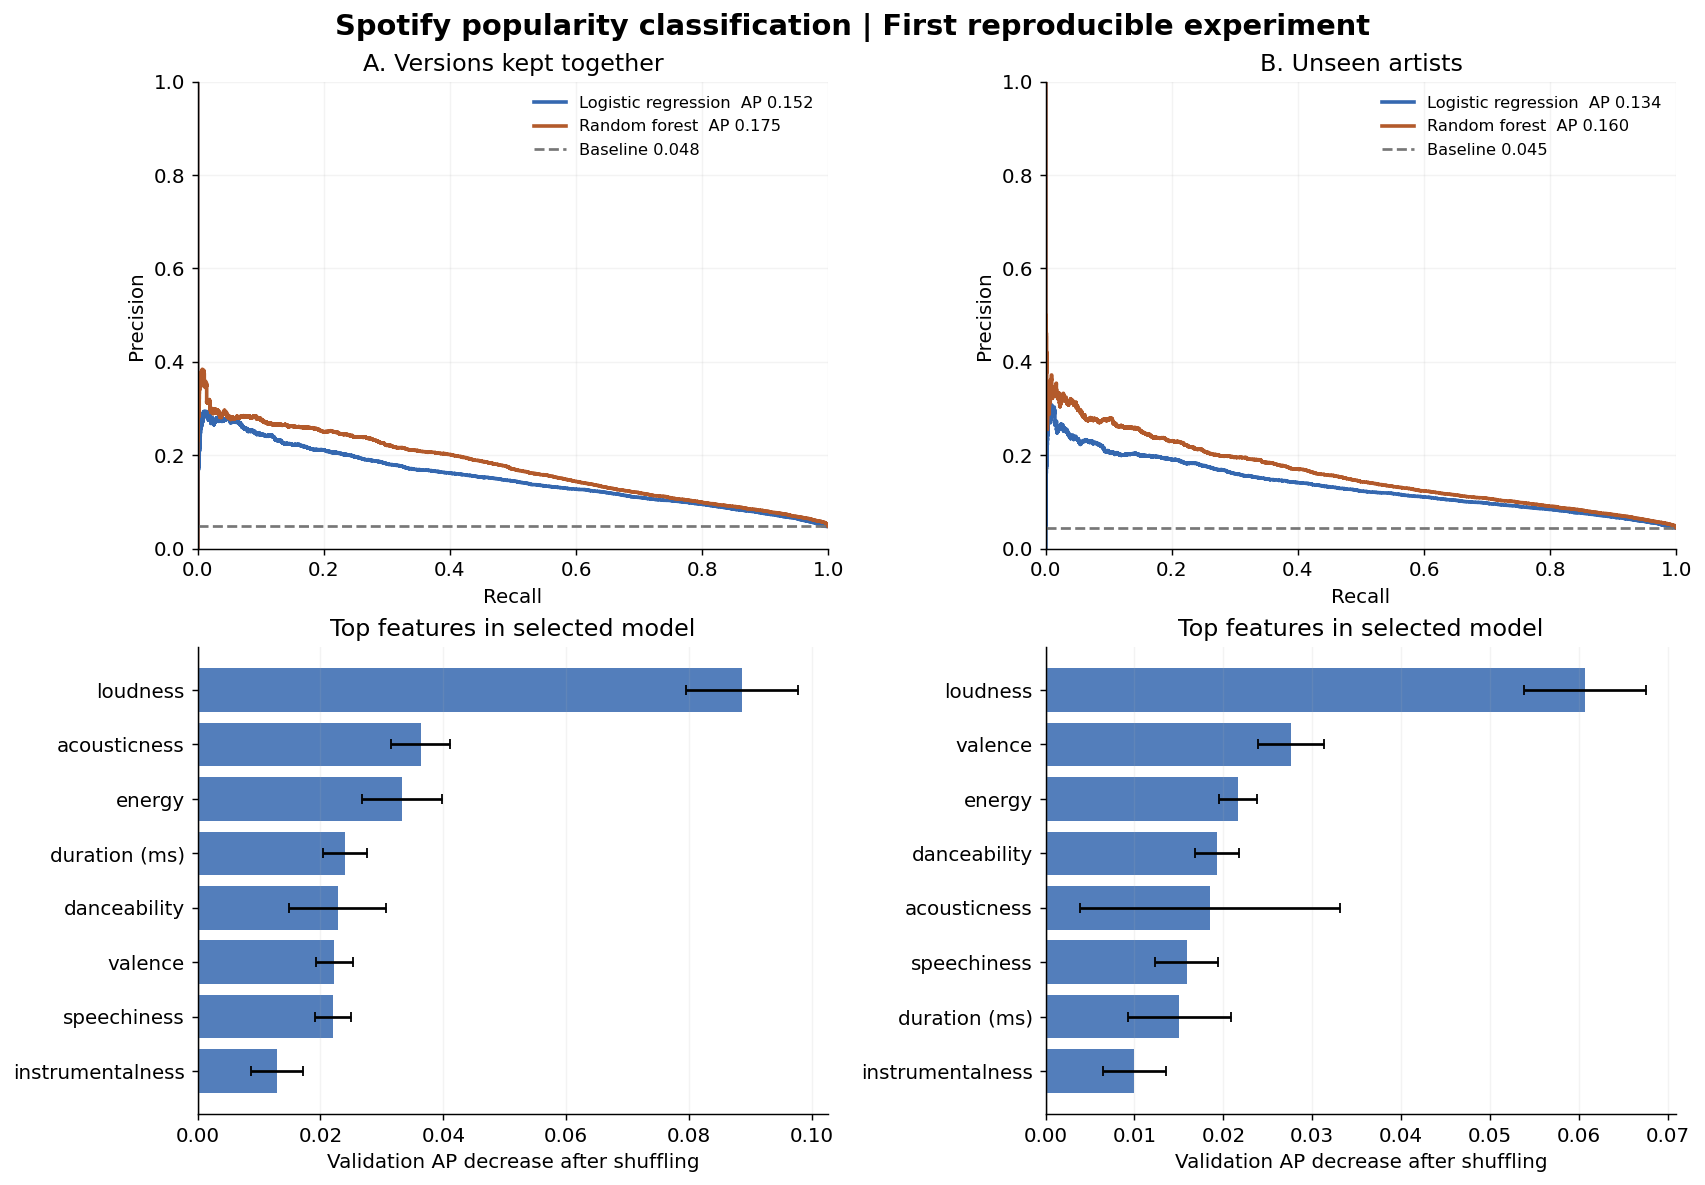

Completed. Models are fitted on their respective training sets only; no post-test tuning.


In [5]:
importance_rows=[]
for experiment,parts in splits.items():
    val=np.flatnonzero(parts=='validation')
    sample,_=train_test_split(val,train_size=min(10000,len(val)-1),stratify=y[val],random_state=SEED)
    model=fitted[experiment][decisions[experiment]['selected_model']]['model']
    sample_x=X.iloc[sample].copy(); sample_y=y[sample]
    base=average_precision_score(sample_y,model.predict_proba(sample_x)[:,1])
    rng=np.random.default_rng(SEED)
    for feature in FEATURES:
        drops=[]
        for repeat in range(3):
            shuffled=sample_x.copy()
            shuffled[feature]=rng.permutation(shuffled[feature].to_numpy())
            drops.append(float(base-average_precision_score(sample_y,model.predict_proba(shuffled)[:,1])))
        importance_rows.append({'experiment':experiment,'feature':feature,'mean_ap_drop':float(np.mean(drops)),
                                'std_ap_drop':float(np.std(drops)),'validation_sample_rows':len(sample),'sample_base_ap':float(base)})
    print('Permutation interpretation completed:',experiment,flush=True)
importance_results=pd.DataFrame(importance_rows)
display(importance_results.sort_values(['experiment','mean_ap_drop'],ascending=[True,False]).round(5))
importance_results.to_json(OUT/'validation_permutation_importance.json',orient='records',indent=2)

plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(2,2,figsize=(13,9),layout='constrained')
colors={'logistic_regression':'#3568b0','forest_depth12':'#b35a2b','forest_depth20':'#b35a2b'}
titles={'version_grouped':'A. Versions kept together','artist_disjoint':'B. Unseen artists'}
for col,experiment in enumerate(splits):
    info=test_predictions[experiment]; ax=axes[0,col]
    for name,scores in info['scores'].items():
        if name=='constant_baseline': continue
        p,r,_=precision_recall_curve(info['y'],scores)
        ap=average_precision_score(info['y'],scores)
        label='Logistic regression' if name=='logistic_regression' else 'Random forest'
        ax.step(r,p,where='post',color=colors[name],lw=2,label=f'{label}  AP {ap:.3f}')
    ax.axhline(info['y'].mean(),ls='--',color='#777777',label=f'Baseline {info["y"].mean():.3f}')
    ax.set(xlim=(0,1),ylim=(0,1),xlabel='Recall',ylabel='Precision',title=titles[experiment])
    ax.legend(loc='upper right',frameon=False,fontsize=9)
    ax.grid(alpha=.15)
    imp=importance_results.loc[importance_results.experiment.eq(experiment)].nlargest(8,'mean_ap_drop').sort_values('mean_ap_drop')
    ax=axes[1,col]
    labels=imp.feature.replace({'duration_ms':'duration (ms)'})
    ax.barh(labels,imp.mean_ap_drop,xerr=imp.std_ap_drop,color='#3568b0',alpha=.85,capsize=3)
    ax.axvline(0,color='#777777',lw=.8)
    ax.set(xlabel='Validation AP decrease after shuffling',title='Top features in selected model')
    ax.grid(axis='x',alpha=.15)
fig.suptitle('Spotify popularity classification | First reproducible experiment',fontsize=16,fontweight='bold')
fig.savefig(OUT/'model_overview.png',dpi=180,bbox_inches='tight')
display(fig)
plt.close(fig)

metadata={'dataset_sha256':digest.hexdigest(),'seed':SEED,'target_threshold':THRESHOLD,'source_rows':len(raw),
          'versions':versions,'features':FEATURES,'duration_input_unit':'milliseconds, original source values',
          'decisions':decisions,'primary_metric':'average_precision_score, not trapezoidal PR-AUC',
          'probability_calibrated':False,'test_used_for_tuning':False}
(OUT/'experiment_metadata.json').write_text(json.dumps(metadata,indent=2))
print('Completed. Models are fitted on their respective training sets only; no post-test tuning.')